# City Hospital – Pré-processamento, ABT e Análise Exploratória
Versão simplificada do `Main.py` em formato notebook.

**Passos:** 1) Carregar dados → 2) Limpar → 3) Construir a ABT (1 linha por paciente) → 4) Gráficos → 5) Guardar resultados.

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## 1. Carregar e inspecionar os dados

In [32]:
df_raw = pd.read_excel("Project Data nova.xlsx")

print(f"{df_raw.shape[0]:,} linhas x {df_raw.shape[1]} colunas")
print("Pacientes únicos:", df_raw["Patient ID"].nunique())
print("Linhas duplicadas:", df_raw.duplicated().sum())
df_raw.head()

10,008 linhas x 16 colunas
Pacientes únicos: 500
Linhas duplicadas: 8


,Patient ID,Age,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Visit Date,Department,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage
0,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-02-22,Endocrinology,110,2,38839.0,293.014042,0.0
1,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-01-21,Emergency,76,4,52219.0,287.208982,0.0
2,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-06-13,Neurology,17,5,41491.0,241.254507,0.0
3,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-03-24,Emergency,15,3,34944.0,221.177483,0.0
4,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-03-19,Neurology,99,1,39248.0,219.743794,0.0


In [33]:
pd.DataFrame({"tipo": df_raw.dtypes.astype(str),
              "em falta": df_raw.isnull().sum(),
              "% em falta": (df_raw.isnull().mean() * 100).round(2)})

,tipo,em falta,% em falta
Patient ID,int64,0,0.00
Age,float64,56,0.56
Gender,str,0,0.00
City of Residence,str,0,0.00
Profession,str,0,0.00
Insurance Provider,str,1910,19.08
Family History,str,1993,19.91
Education Level,str,29,0.29
Marital Status,str,0,0.00
Visit Date,datetime64[us],0,0.00


In [34]:
df_raw.describe().round(1)

,Patient ID,Age,Visit Date,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage
count,10008.0,9952.0,10008,10008.0,10008.0,9854.0,10008.0,9958.0
mean,1251.6,50.6,2024-03-31 14:53:14.244604,67.8,3.2,43402.8,187.3,115.4
min,1000.0,0.0,2024-01-01 00:00:00,15.0,1.0,0.0,50.0,0.0
25%,1127.0,23.0,2024-02-15 00:00:00,41.0,2.0,31157.8,111.3,59.7
50%,1252.0,52.0,2024-03-31 00:00:00,68.0,3.0,40876.5,159.5,115.9
75%,1375.0,75.0,2024-05-16 00:00:00,94.0,5.0,50721.8,199.8,165.4
max,1499.0,195.0,2024-06-30 00:00:00,600.0,6.0,11970900.0,39999.2,421.9
std,144.6,31.2,NaN,32.4,1.6,268142.0,862.9,79.3


## 2. Limpeza dos dados
| Problema | Tratamento |
|---|---|
| Linhas duplicadas | Remover |
| Idades > 100 (erros de digitação) | Passar a vazio (NaN) e imputar depois |
| Atributos do paciente que mudam entre visitas | Usar o valor mais recente |
| Menores de 18 com profissão/estado civil de adulto | Corrigir para *Student* / *Single* |
| Satisfação = 6 (escala é 1–5) | Limitar a 5 |
| Duração, preço e rendimento com valores extremos | Regra do IQR (1.5 × IQR) |
| Valores em falta | Mediana (numéricos) / moda (categóricos) |
| Cobertura do seguro > preço | Limitar ao preço |

In [35]:
df = df_raw.drop_duplicates().copy()
df["Visit Date"] = pd.to_datetime(df["Visit Date"])
df = df.sort_values(["Patient ID", "Visit Date"]).reset_index(drop=True)
print("Linhas após remover duplicados:", len(df))

# Idades impossíveis -> NaN
df.loc[df["Age"] > 100, "Age"] = np.nan

# Atributos estáticos: ficar com o último valor não nulo de cada paciente
static_cols = ["Age", "Gender", "City of Residence", "Profession", "Insurance Provider",
               "Family History", "Education Level", "Marital Status"]
for col in static_cols:
    df[col] = df["Patient ID"].map(df.dropna(subset=[col]).groupby("Patient ID")[col].last())

# Menores de idade
minor = df["Age"] < 18
df.loc[minor, "Profession"] = "Student"
df.loc[minor, "Marital Status"] = "Single"

Linhas após remover duplicados: 10000


In [36]:
# Satisfação: escala 1-5
print("Satisfação = 6:", (df["Satisfaction Level"] > 5).sum())
df["Satisfaction Level"] = df["Satisfaction Level"].clip(1, 5)

def iqr_upper(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return q3 + 1.5 * (q3 - q1)

# Duração: limitar ao limite superior do IQR
df["Consultation Duration"] = df["Consultation Duration"].clip(upper=iqr_upper(df["Consultation Duration"]))

# Preço: limite do IQR por departamento
df["Consultation Price"] = df.groupby("Department")["Consultation Price"].transform(
    lambda s: s.clip(upper=iqr_upper(s)))

# Rendimento: estudantes = 0; restantes com valores absurdos -> NaN
adult = df["Profession"] != "Student"
inc_fence = iqr_upper(df.loc[adult & (df["Approximate Annual Income"] > 0), "Approximate Annual Income"])
print(f"Limite superior de rendimento: £{inc_fence:,.0f}")
df.loc[adult & ((df["Approximate Annual Income"] > inc_fence) | (df["Approximate Annual Income"] == 0)),
       "Approximate Annual Income"] = np.nan
df.loc[~adult, "Approximate Annual Income"] = 0.0

Satisfação = 6: 719
Limite superior de rendimento: £75,534


In [37]:
# Valores em falta
df["Family History"] = df["Family History"].fillna("None")
df["Insurance Provider"] = df["Insurance Provider"].fillna("Uninsured")

df["Age"] = df["Age"].fillna(df["Age"].median())
df["Education Level"] = df["Education Level"].fillna(df["Education Level"].mode()[0])
df["Approximate Annual Income"] = df["Approximate Annual Income"].fillna(
    df.groupby("Profession")["Approximate Annual Income"].transform("median"))

# Cobertura do seguro
df.loc[(df["Insurance Provider"] == "Uninsured") & df["Insurance Coverage"].isna(), "Insurance Coverage"] = 0
df["Insurance Coverage"] = df["Insurance Coverage"].fillna(
    df.groupby("Insurance Provider")["Insurance Coverage"].transform("median"))
df["Insurance Coverage"] = np.minimum(df["Insurance Coverage"].clip(lower=0), df["Consultation Price"])
df["Out_of_Pocket"] = df["Consultation Price"] - df["Insurance Coverage"]

df_clean = df
print("Valores em falta restantes:", df_clean.isnull().sum().sum())
print("Pacientes:", df_clean["Patient ID"].nunique())

Valores em falta restantes: 0
Pacientes: 500


## 3. Construção da ABT (Analytic Base Table)
Uma linha por paciente (500), com características demográficas, de comportamento, financeiras, de satisfação e de recência. Data de referência: 1 de julho de 2024.

In [38]:
ref_date = pd.Timestamp("2024-07-01")
df_clean["Is_Weekend"] = (df_clean["Visit Date"].dt.dayofweek >= 5).astype(int)
df_clean["Is_Low_Sat"] = (df_clean["Satisfaction Level"] <= 2).astype(int)

abt = df_clean.groupby("Patient ID").agg(
    Age=("Age", "last"),
    Gender=("Gender", "last"),
    City=("City of Residence", "last"),
    Profession=("Profession", "last"),
    Insurance_Provider=("Insurance Provider", "last"),
    Family_History=("Family History", "last"),
    Education_Level=("Education Level", "last"),
    Marital_Status=("Marital Status", "last"),
    Annual_Income=("Approximate Annual Income", "mean"),
    # comportamento
    Total_Visits=("Visit Date", "count"),
    Distinct_Departments=("Department", "nunique"),
    Top_Department=("Department", lambda s: s.value_counts().index[0]),
    Avg_Duration=("Consultation Duration", "mean"),
    Weekend_Visits=("Is_Weekend", "sum"),
    # financeiro
    Total_Price=("Consultation Price", "sum"),
    Total_Coverage=("Insurance Coverage", "sum"),
    Total_Out_of_Pocket=("Out_of_Pocket", "sum"),
    # satisfação
    Avg_Satisfaction=("Satisfaction Level", "mean"),
    Low_Rating_Count=("Is_Low_Sat", "sum"),
    # recência
    First_Visit=("Visit Date", "min"),
    Last_Visit=("Visit Date", "max"),
).reset_index()

abt["Age_Group"] = pd.cut(abt["Age"], bins=range(0, 110, 10), right=False,
                          labels=[f"{i}-{i+9}" for i in range(0, 100, 10)])
abt["Income_Quartile"] = pd.qcut(abt["Annual_Income"].rank(method="first"), 4,
                                 labels=["Q1 (Lowest)", "Q2", "Q3", "Q4 (Highest)"])
abt["Weekend_Share"] = abt["Weekend_Visits"] / abt["Total_Visits"]
abt["Out_of_Pocket_Ratio"] = abt["Total_Out_of_Pocket"] / abt["Total_Price"]
abt["Share_Low_Ratings"] = abt["Low_Rating_Count"] / abt["Total_Visits"]
abt["Days_Since_Last_Visit"] = (ref_date - abt["Last_Visit"]).dt.days
abt["Active_Span_Days"] = (abt["Last_Visit"] - abt["First_Visit"]).dt.days.clip(lower=1)
abt["Visits_Per_Month"] = abt["Total_Visits"] / 6
abt = abt.drop(columns=["First_Visit", "Last_Visit"]).round(2)

assert len(abt) == 500
print(abt.shape)
abt.head()

(500, 28)


,Patient ID,Age,Gender,City,Profession,Insurance_Provider,Family_History,Education_Level,Marital_Status,Annual_Income,Total_Visits,Distinct_Departments,Top_Department,Avg_Duration,Weekend_Visits,Total_Price,Total_Coverage,Total_Out_of_Pocket,Avg_Satisfaction,Low_Rating_Count,Age_Group,Income_Quartile,Weekend_Share,Out_of_Pocket_Ratio,Share_Low_Ratings,Days_Since_Last_Visit,Active_Span_Days,Visits_Per_Month
0,1000,51.0,Female,Birmingham,Artist,Provider D,Hypertension,Undergraduate,Divorced,43667.25,20,10,Allergology,65.70,6,3504.03,3504.03,0.00,2.60,10,50-59,Q2,0.30,0.0,0.50,4,178,3.33
1,1001,55.0,Male,Liverpool,Lawyer,Provider C,Heart Disease,Undergraduate,Married,44214.44,16,10,ENT,60.50,5,2396.99,1677.89,719.10,3.19,6,50-59,Q3,0.31,0.3,0.38,4,177,2.67
2,1002,10.0,Female,Liverpool,Student,Provider C,Cancer,Elementary school,Single,0.00,18,10,Psychiatry,71.06,6,2919.25,2043.48,875.78,3.44,4,10-19,Q1 (Lowest),0.33,0.3,0.22,8,169,3.00
3,1003,91.0,Male,Manchester,Retired,Provider A,Cancer,Master,Married,42711.66,25,11,Psychiatry,61.40,5,4486.11,3588.89,897.22,3.24,9,90-99,Q2,0.20,0.2,0.36,2,178,4.17
4,1004,11.0,Male,Glasgow,Student,Provider B,Cancer,Middle school/junior high,Single,0.00,26,9,General Practice,62.65,5,4486.14,4037.53,448.61,3.27,10,10-19,Q1 (Lowest),0.19,0.1,0.38,3,179,4.33


## 4. Visualizações

### 4.1 Demografia dos pacientes

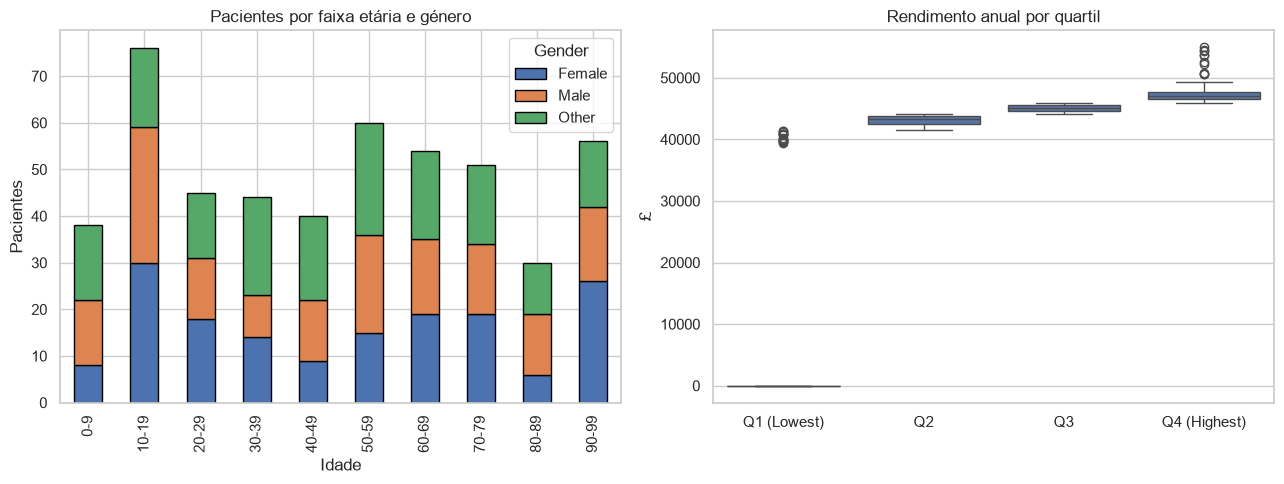

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
pd.crosstab(abt["Age_Group"], abt["Gender"]).plot(kind="bar", stacked=True, ax=ax[0], edgecolor="black")
ax[0].set_title("Pacientes por faixa etária e género"); ax[0].set_xlabel("Idade"); ax[0].set_ylabel("Pacientes")
sns.boxplot(data=abt, x="Income_Quartile", y="Annual_Income", ax=ax[1])
ax[1].set_title("Rendimento anual por quartil"); ax[1].set_xlabel(""); ax[1].set_ylabel("£")
plt.tight_layout(); plt.show()

### 4.2 Utilização dos departamentos

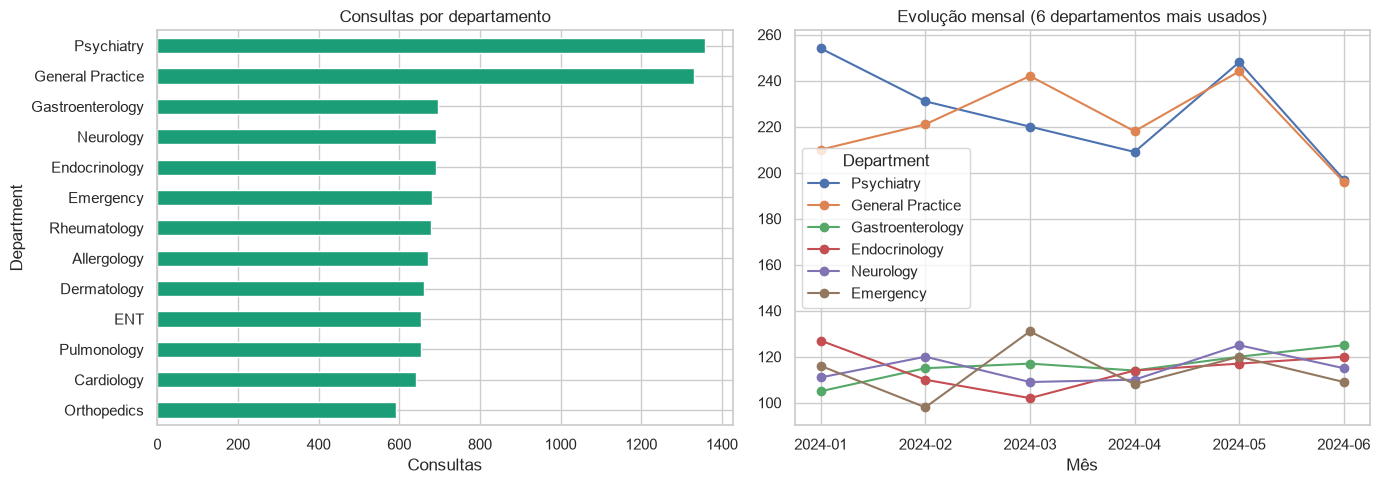

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
df_clean["Department"].value_counts().sort_values().plot(kind="barh", ax=ax[0], color="#1b9e77")
ax[0].set_title("Consultas por departamento"); ax[0].set_xlabel("Consultas")

monthly = (df_clean.assign(Month=df_clean["Visit Date"].dt.to_period("M").astype(str))
           .groupby(["Month", "Department"]).size().unstack(fill_value=0))
monthly[df_clean["Department"].value_counts().index[:6]].plot(ax=ax[1], marker="o")
ax[1].set_title("Evolução mensal (6 departamentos mais usados)"); ax[1].set_xlabel("Mês")
plt.tight_layout(); plt.show()

### 4.3 Departamento por género e idade

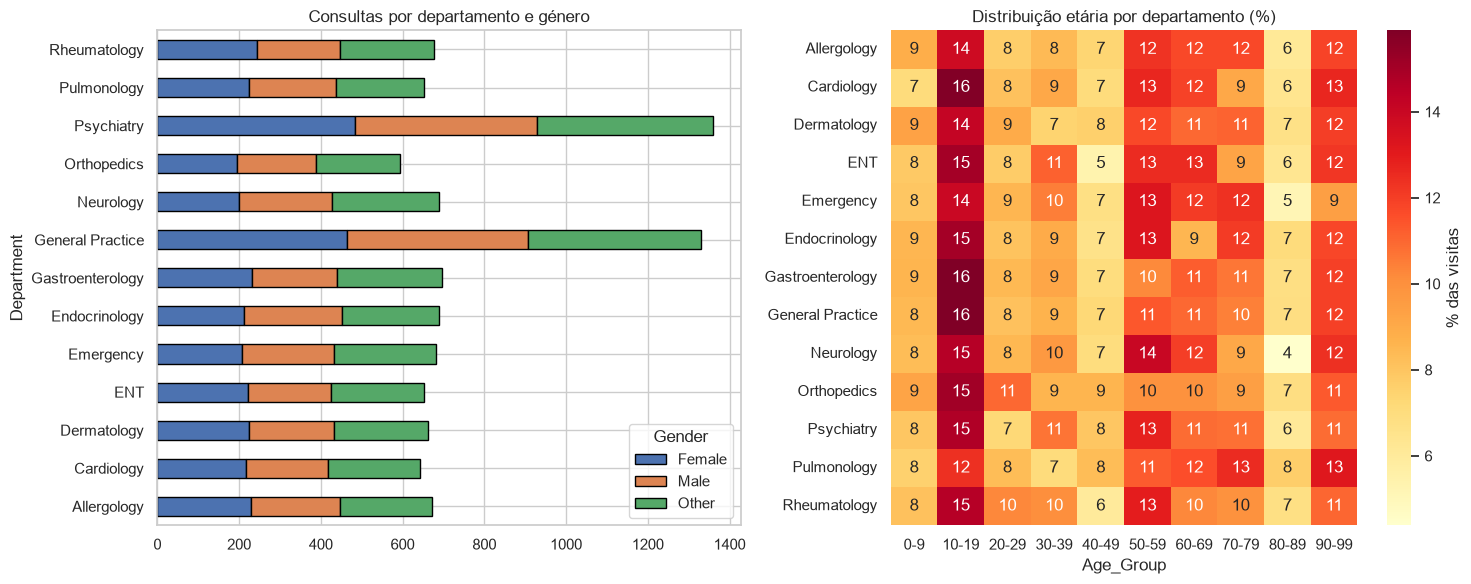

In [41]:
d = df_clean.merge(abt[["Patient ID", "Age_Group"]], on="Patient ID")
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
pd.crosstab(d["Department"], d["Gender"]).plot(kind="barh", stacked=True, ax=ax[0], edgecolor="black")
ax[0].set_title("Consultas por departamento e género")
sns.heatmap(pd.crosstab(d["Department"], d["Age_Group"], normalize="index") * 100,
            annot=True, fmt=".0f", cmap="YlOrRd", ax=ax[1], cbar_kws={"label": "% das visitas"})
ax[1].set_title("Distribuição etária por departamento (%)"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

### 4.4 Satisfação por departamento

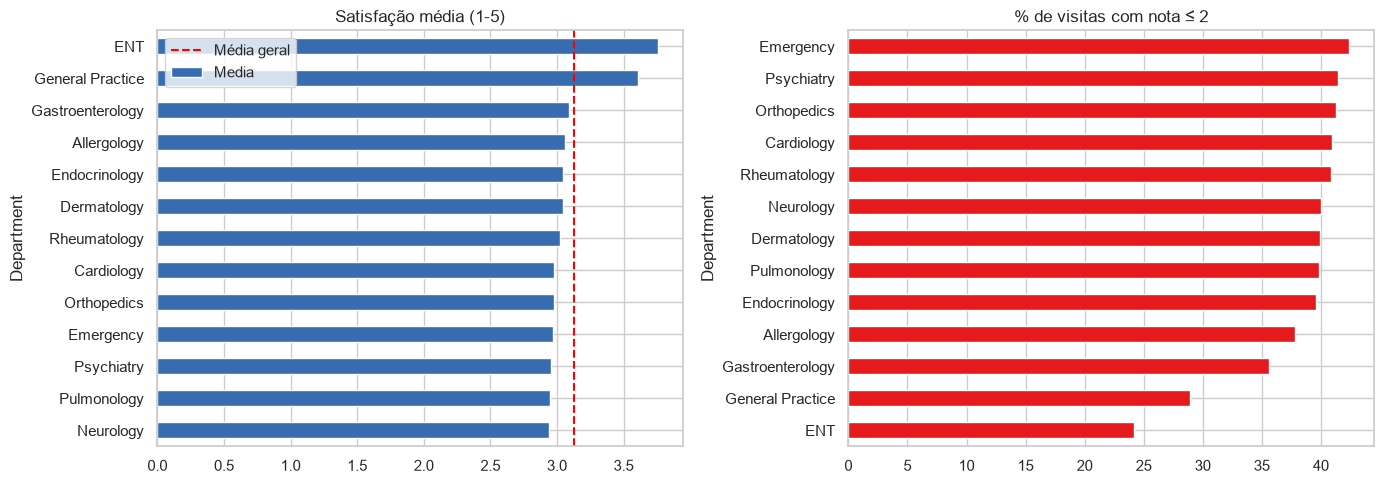

In [42]:
sat = df_clean.groupby("Department").agg(Media=("Satisfaction Level", "mean"),
                                           Baixa=("Is_Low_Sat", "mean")).sort_values("Media")
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sat["Media"].plot(kind="barh", ax=ax[0], color="#386cb0")
ax[0].axvline(df_clean["Satisfaction Level"].mean(), color="red", ls="--", label="Média geral")
ax[0].set_title("Satisfação média (1-5)"); ax[0].legend()
(sat["Baixa"] * 100).sort_values().plot(kind="barh", ax=ax[1], color="#e41a1c")
ax[1].set_title("% de visitas com nota ≤ 2")
plt.tight_layout(); plt.show()

### 4.5 Satisfação por segmento de paciente

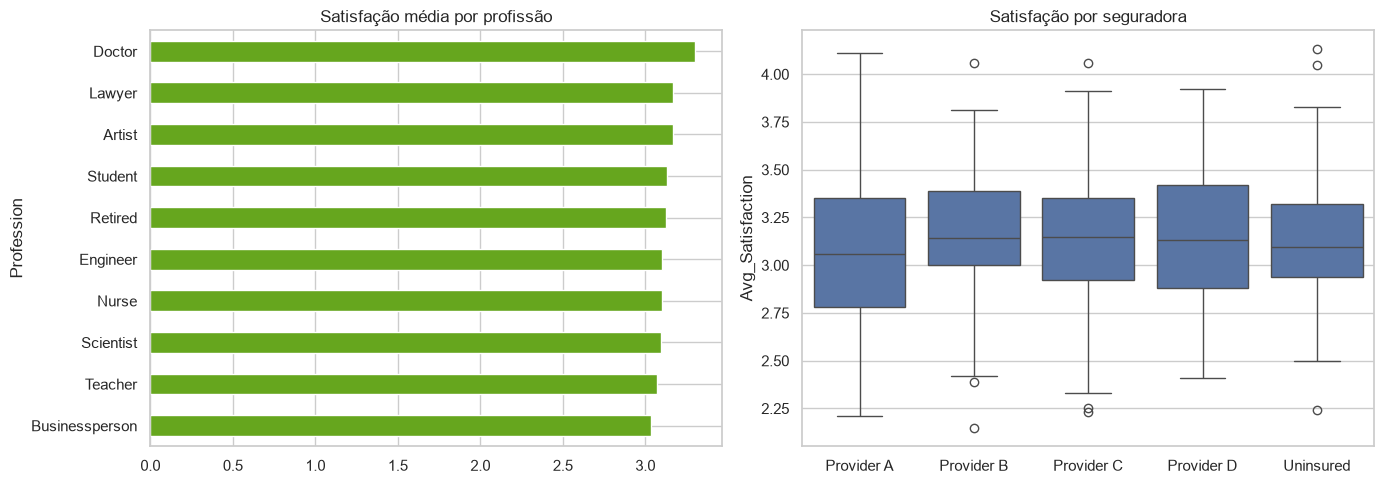

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
abt.groupby("Profession")["Avg_Satisfaction"].mean().sort_values().plot(kind="barh", ax=ax[0], color="#66a61e")
ax[0].set_title("Satisfação média por profissão")
sns.boxplot(data=abt, x="Insurance_Provider", y="Avg_Satisfaction", ax=ax[1],
            order=["Provider A", "Provider B", "Provider C", "Provider D", "Uninsured"])
ax[1].set_title("Satisfação por seguradora"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

### 4.6 Custos: seguro vs. paciente

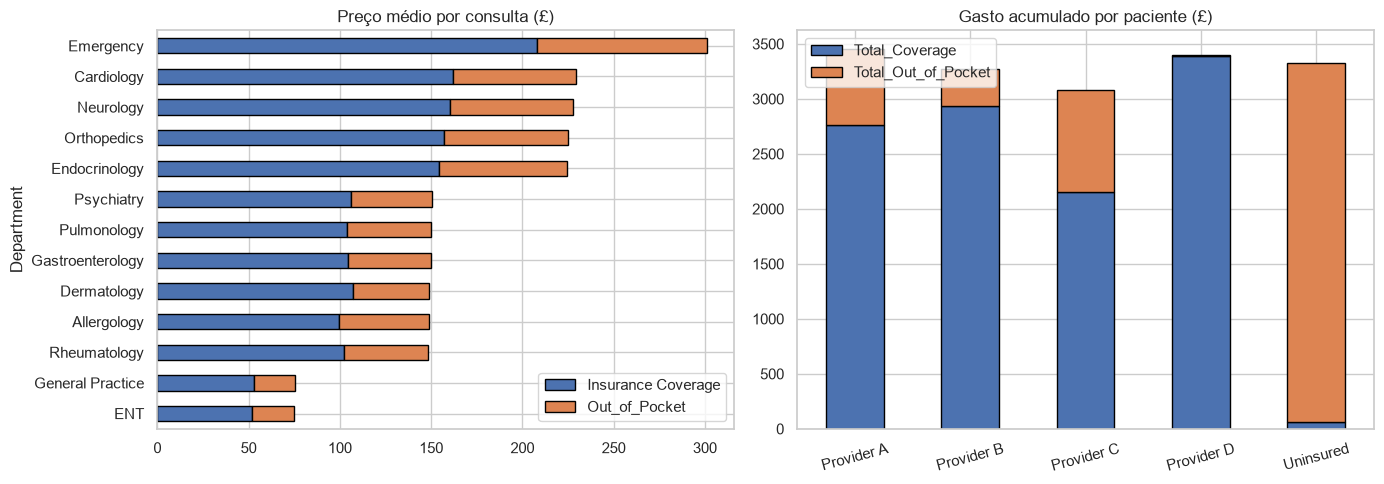

In [44]:
fin = df_clean.groupby("Department")[["Insurance Coverage", "Out_of_Pocket"]].mean()
fin = fin.loc[fin.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
fin.plot(kind="barh", stacked=True, ax=ax[0], edgecolor="black")
ax[0].set_title("Preço médio por consulta (£)")
abt.groupby("Insurance_Provider")[["Total_Coverage", "Total_Out_of_Pocket"]].mean().reindex(
    ["Provider A", "Provider B", "Provider C", "Provider D", "Uninsured"]).plot(
    kind="bar", stacked=True, ax=ax[1], edgecolor="black")
ax[1].set_title("Gasto acumulado por paciente (£)"); ax[1].set_xlabel(""); ax[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

## 5. Guardar resultados

In [45]:
abt.to_csv("ABT_city_hospital.csv", index=False)
print("Guardado: ABT_city_hospital.csv", abt.shape)

Guardado: ABT_city_hospital.csv (500, 28)
